In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, classification_report,
    precision_recall_curve, silhouette_samples
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.model_selection import TimeSeriesSplit

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# --- بارگیری و ساخت df_valid (اگر از قبل ندارید) ---
if "df_valid" not in dir():
    online_retail = fetch_ucirepo(id=352)
    df_raw = online_retail.data.original.copy()
    for col in ["Unnamed: 0", "index", ""]:
        if col in df_raw.columns:
            df_raw = df_raw.drop(columns=[col])

    df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"], errors="coerce")
    df_raw["CustomerID"]  = pd.to_numeric(df_raw["CustomerID"], errors="coerce").astype("Int64")
    df_raw["InvoiceNo"]   = df_raw["InvoiceNo"].astype(str)
    df_raw["StockCode"]   = df_raw["StockCode"].astype(str)
    df_raw["Quantity"]    = pd.to_numeric(df_raw["Quantity"], errors="coerce")
    df_raw["UnitPrice"]   = pd.to_numeric(df_raw["UnitPrice"], errors="coerce")
    df_raw["IsCancelled"] = df_raw["InvoiceNo"].str.startswith("C")

    _tmp = df_raw.dropna(subset=["CustomerID"]).drop_duplicates()
    df_valid = _tmp[(~_tmp["IsCancelled"]) &
                    (_tmp["Quantity"] > 0) &
                    (_tmp["UnitPrice"] > 0)].copy()
    df_valid["CustomerID"] = df_valid["CustomerID"].astype(int)
    df_valid["TotalPrice"] = df_valid["Quantity"] * df_valid["UnitPrice"]

    print("df_valid:", df_valid.shape,
          "| customers:", df_valid["CustomerID"].nunique())

df_valid: (392692, 10) | customers: 4338


In [2]:
OBS_DAYS   = 180
LABEL_DAYS = 90

REFERENCE_DATES = [
    pd.Timestamp("2011-06-01"),
    pd.Timestamp("2011-07-01"),
    pd.Timestamp("2011-08-01"),
    pd.Timestamp("2011-09-01"),
]

CLUSTER_FEATURES = [
    "Recency","Frequency","Monetary","TenureDays","AvgOrderValue",
    "DistinctProducts","ActiveDays","Freq_change","Monetary_change",
    "Cancel_rate","Return_rate","Product_diversity","AvgGap",
    "Monthly_orders_std",
]

FEATURE_COLS = CLUSTER_FEATURES + ["First_last_span", "Cluster"]

In [3]:
def build_churn_labels(df_valid, ref_date):
    """برچسب ریزش: عدم خرید معتبر در ۹۰ روز پس از تاریخ مرجع."""
    obs_start = ref_date - pd.Timedelta(days=OBS_DAYS)
    label_end = ref_date + pd.Timedelta(days=LABEL_DAYS)

    obs_customers = set(df_valid.loc[
        (df_valid["InvoiceDate"] >= obs_start) &
        (df_valid["InvoiceDate"] < ref_date), "CustomerID"].unique())

    future_buyers = set(df_valid.loc[
        (df_valid["InvoiceDate"] >= ref_date) &
        (df_valid["InvoiceDate"] < label_end), "CustomerID"].unique())

    labels = pd.DataFrame({"CustomerID": sorted(obs_customers)})
    labels["Churn"] = labels["CustomerID"].apply(lambda c: 0 if c in future_buyers else 1)
    labels["ReferenceDate"] = ref_date
    return labels


def build_features_for_ref(df_valid, df_raw, ref_date, cluster_labels=None):
    """۱۶ ویژگی رفتاری فقط از ۱۸۰ روز قبل از تاریخ مرجع."""
    obs_start = ref_date - pd.Timedelta(days=OBS_DAYS)
    obs = df_valid[(df_valid["InvoiceDate"] >= obs_start) &
                   (df_valid["InvoiceDate"] < ref_date)].copy()

    rfm = obs.groupby("CustomerID").agg(
        Recency          = ("InvoiceDate", lambda x: (ref_date - x.max()).days),
        Frequency        = ("InvoiceNo", "nunique"),
        Monetary         = ("TotalPrice", "sum"),
        FirstPurchase    = ("InvoiceDate", "min"),
        LastPurchase     = ("InvoiceDate", "max"),
        DistinctProducts = ("StockCode", "nunique"),
        ActiveDays       = ("InvoiceDate", lambda x: x.dt.normalize().nunique()),
        TotalRows        = ("InvoiceNo", "size"),
    ).reset_index()

    rfm["TenureDays"]        = (ref_date - rfm["FirstPurchase"]).dt.days
    rfm["First_last_span"]   = (rfm["LastPurchase"] - rfm["FirstPurchase"]).dt.days
    rfm["AvgOrderValue"]     = rfm["Monetary"] / rfm["Frequency"]
    rfm["Product_diversity"] = rfm["DistinctProducts"] / rfm["TotalRows"]
    rfm["AvgGap"] = np.where(rfm["Frequency"] > 1,
                             rfm["First_last_span"] / (rfm["Frequency"] - 1),
                             rfm["First_last_span"])

    # تغییر رفتار: نیمه اول vs نیمه دوم
    mid = ref_date - pd.Timedelta(days=OBS_DAYS // 2)
    f1 = obs[obs["InvoiceDate"] <  mid].groupby("CustomerID").agg(
        F1=("InvoiceNo","nunique"), M1=("TotalPrice","sum"))
    f2 = obs[obs["InvoiceDate"] >= mid].groupby("CustomerID").agg(
        F2=("InvoiceNo","nunique"), M2=("TotalPrice","sum"))
    change = f1.join(f2, how="outer").fillna(0)
    change["Freq_change"]     = change["F2"] - change["F1"]
    change["Monetary_change"] = change["M2"] - change["M1"]

    rfm = rfm.merge(change.reset_index()[["CustomerID","Freq_change","Monetary_change"]],
                    on="CustomerID", how="left").fillna({"Freq_change":0,"Monetary_change":0})

    # انحراف معیار سفارش‌های ماهانه
    obs["Month"] = obs["InvoiceDate"].dt.to_period("M")
    monthly = obs.groupby(["CustomerID","Month"])["InvoiceNo"].nunique().reset_index()
    monthly_std = monthly.groupby("CustomerID")["InvoiceNo"].std().rename("Monthly_orders_std")
    rfm = rfm.merge(monthly_std.reset_index(), on="CustomerID", how="left")
    rfm["Monthly_orders_std"] = rfm["Monthly_orders_std"].fillna(0)

    # نرخ لغو و مرجوعی (از دیتاست خام، نه خرید معتبر)
    raw_obs = df_raw[(df_raw["InvoiceDate"] >= obs_start) &
                     (df_raw["InvoiceDate"] < ref_date) &
                     (df_raw["CustomerID"].notna())].copy()
    raw_obs["CustomerID"] = raw_obs["CustomerID"].astype(int)

    total_inv = raw_obs.groupby("CustomerID")["InvoiceNo"].nunique().rename("TotalInvoices")
    cancels   = raw_obs[raw_obs["IsCancelled"]].groupby("CustomerID")["InvoiceNo"].nunique().rename("CancelCount")
    returns   = raw_obs[(raw_obs["Quantity"] < 0) & (~raw_obs["IsCancelled"])].groupby("CustomerID").size().rename("ReturnCount")

    rates = pd.concat([total_inv, cancels, returns], axis=1).fillna(0)
    rates["Cancel_rate"] = rates["CancelCount"] / rates["TotalInvoices"].replace(0, np.nan)
    rates["Return_rate"] = rates["ReturnCount"] / rates["TotalInvoices"].replace(0, np.nan)

    rfm = rfm.merge(rates.reset_index()[["CustomerID","Cancel_rate","Return_rate"]],
                    on="CustomerID", how="left")
    rfm[["Cancel_rate","Return_rate"]] = rfm[["Cancel_rate","Return_rate"]].fillna(0)

    if cluster_labels is not None:
        rfm = rfm.merge(cluster_labels, on="CustomerID", how="left")
        rfm["Cluster"] = rfm["Cluster"].fillna(-1).astype(int)

    rfm["ReferenceDate"] = ref_date
    return rfm

In [4]:
all_feats_no_cluster = [build_features_for_ref(df_valid, df_raw, d) for d in REFERENCE_DATES]
feats_for_cluster = pd.concat(all_feats_no_cluster, ignore_index=True)

print("Feature matrix shape:", feats_for_cluster.shape)
print("Customers (unique):", feats_for_cluster["CustomerID"].nunique())

# کاهش چولگی و استانداردسازی
Xc = feats_for_cluster[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0).copy()
for col in ["Monetary","Frequency","AvgOrderValue","DistinctProducts"]:
    Xc[col] = np.log1p(Xc[col].clip(lower=0))
Xc_scaled = StandardScaler().fit_transform(Xc)

Feature matrix shape: (10926, 20)
Customers (unique): 3267


   K      Inertia  Silhouette
0  2  106788.9349      0.2741
1  3   93104.1207      0.2370
2  4   80867.2972      0.2432
3  5   75010.0196      0.2404
4  6   69968.7945      0.2513
5  7   66228.5249      0.2205
6  8   62244.3570      0.2202

K بهینه (Silhouette): 2


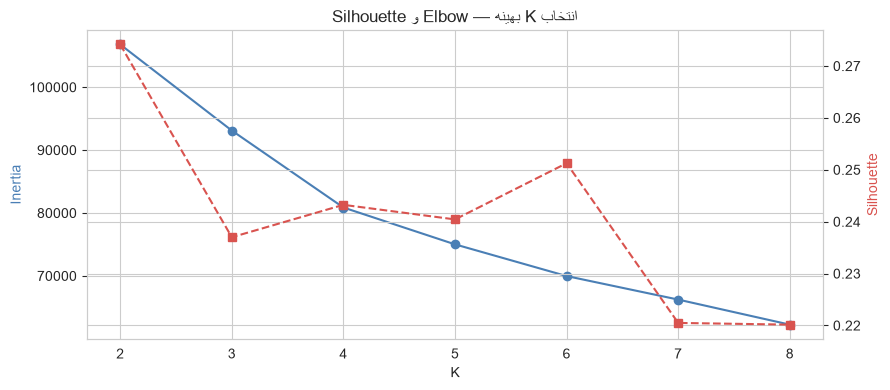

In [5]:
inertias, sils = [], []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lab = km.fit_predict(Xc_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xc_scaled, lab, sample_size=5000,
                                 random_state=RANDOM_STATE))

k_table = pd.DataFrame({"K": list(K_range), "Inertia": inertias, "Silhouette": sils})
print(k_table.round(4))

best_k = int(k_table.sort_values("Silhouette", ascending=False).iloc[0]["K"])
print(f"\nK بهینه (Silhouette): {best_k}")

# نمودار Elbow + Silhouette
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(k_table["K"], k_table["Inertia"], "o-", color="#4a7fb5", label="Inertia")
ax1.set_xlabel("K"); ax1.set_ylabel("Inertia", color="#4a7fb5")
ax2 = ax1.twinx()
ax2.plot(k_table["K"], k_table["Silhouette"], "s--", color="#d9534f", label="Silhouette")
ax2.set_ylabel("Silhouette", color="#d9534f")
plt.title("انتخاب K بهینه — Elbow و Silhouette")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/kmeans_k_selection.png", dpi=120)
plt.show()

In [6]:
km_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
feats_for_cluster["Cluster"] = km_final.fit_predict(Xc_scaled)

cluster_labels_df = feats_for_cluster[["CustomerID","Cluster"]].drop_duplicates("CustomerID")

profile = feats_for_cluster.groupby("Cluster").agg({
    "Recency":"mean","Frequency":"mean","Monetary":"mean","TenureDays":"mean",
    "AvgOrderValue":"mean","DistinctProducts":"mean","Cancel_rate":"mean",
    "CustomerID":"count"
}).rename(columns={"CustomerID":"N_Customers"})

print("پروفایل خوشه‌ها:")
print(profile.round(2))
profile.to_csv(f"{OUT_DIR}/cluster_profile.csv")

# برچسب تجاری بر اساس Recency و Frequency (نگاشت خودکار)
def label_cluster(row, profile):
    r_rank = profile["Recency"].rank()          # 1 = کمترین Recency (بهترین)
    f_rank = profile["Frequency"].rank(ascending=False)  # 1 = بیشترین Frequency
    score = r_rank[row.name] + f_rank[row.name]
    return score

profile["Score"] = [label_cluster(pd.Series({"x":1}, name=i), profile) for i in profile.index]
profile = profile.sort_values("Score")
name_map = {}
labels_cycle = ["Champions","Loyalists","Need Attention","At-Risk","Hibernating"]
for i, cid in enumerate(profile.index):
    name_map[cid] = labels_cycle[min(i, len(labels_cycle)-1)]
profile["Business_Label"] = profile.index.map(name_map)
print("\nنگاشت تجاری:")
print(profile[["Business_Label","Recency","Frequency","Monetary","N_Customers"]].round(2))

feats_for_cluster["Cluster_Label"] = feats_for_cluster["Cluster"].map(name_map)

پروفایل خوشه‌ها:
         Recency  Frequency  Monetary  TenureDays  AvgOrderValue  \
Cluster                                                            
0          83.93       1.22    406.54       90.41         356.28   
1          31.01       4.93   2440.74      139.85         459.41   

         DistinctProducts  Cancel_rate  N_Customers  
Cluster                                              
0                   21.40         0.08         6417  
1                   71.04         0.14         4509  

نگاشت تجاری:
        Business_Label  Recency  Frequency  Monetary  N_Customers
Cluster                                                          
1            Champions    31.01       4.93   2440.74         4509
0            Loyalists    83.93       1.22    406.54         6417


Model dataset: (10926, 22) | base churn: 0.454

نرخ ریزش هر خوشه:
         Churn_Rate     N Business_Label
Cluster                                 
1             0.240  4232      Champions
0             0.589  6694      Loyalists


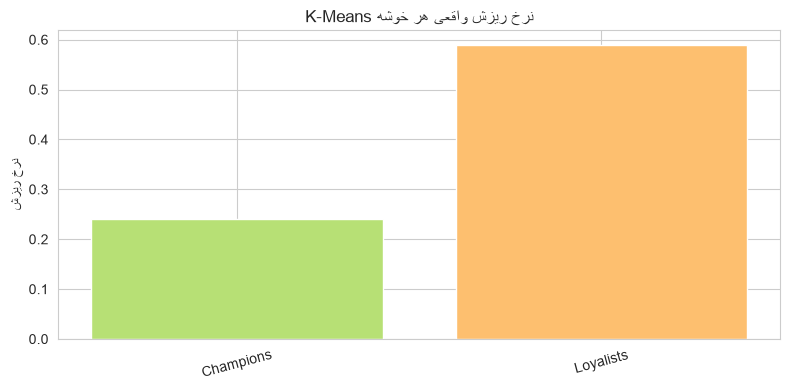

In [7]:
all_rows = []
for d in REFERENCE_DATES:
    feat = build_features_for_ref(df_valid, df_raw, d, cluster_labels=cluster_labels_df)
    lab  = build_churn_labels(df_valid, d)
    all_rows.append(feat.merge(lab, on=["CustomerID","ReferenceDate"], how="inner"))

model_df = pd.concat(all_rows, ignore_index=True)
print("Model dataset:", model_df.shape, "| base churn:", round(model_df["Churn"].mean(),3))

churn_by_cluster = (model_df.groupby("Cluster")["Churn"]
                    .agg(["mean","count"]).rename(columns={"mean":"Churn_Rate","count":"N"})
                    .sort_values("Churn_Rate"))
churn_by_cluster["Business_Label"] = churn_by_cluster.index.map(name_map)
print("\nنرخ ریزش هر خوشه:")
print(churn_by_cluster.round(3))
churn_by_cluster.to_csv(f"{OUT_DIR}/churn_by_cluster.csv")

# نمودار نرخ ریزش خوشه‌ها
plt.figure(figsize=(8, 4))
colors = sns.color_palette("RdYlGn_r", len(churn_by_cluster))
plt.bar(churn_by_cluster["Business_Label"], churn_by_cluster["Churn_Rate"], color=colors)
plt.ylabel("نرخ ریزش")
plt.title("نرخ ریزش واقعی هر خوشه K-Means")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/churn_by_cluster.png", dpi=120)
plt.show()

In [8]:
model_df = model_df.sort_values(["ReferenceDate","CustomerID"]).reset_index(drop=True)

train_dates = [pd.Timestamp("2011-06-01"), pd.Timestamp("2011-07-01")]
test_dates  = [pd.Timestamp("2011-08-01"), pd.Timestamp("2011-09-01")]

train_df = model_df[model_df["ReferenceDate"].isin(train_dates)].copy()
test_df  = model_df[model_df["ReferenceDate"].isin(test_dates)].copy()

def xy(df):
    X = df[FEATURE_COLS].replace([np.inf,-np.inf], np.nan).fillna(0)
    y = df["Churn"].astype(int)
    return X, y

X_train, y_train = xy(train_df)
X_test,  y_test  = xy(test_df)

print(f"Train: {X_train.shape} | churn: {y_train.mean():.3f}")
print(f"Test : {X_test.shape}  | churn: {y_test.mean():.3f}")

Train: (5383, 16) | churn: 0.491
Test : (5543, 16)  | churn: 0.417


In [9]:
def tune_gb(X_tr, y_tr):
    tscv = TimeSeriesSplit(n_splits=3)
    grid = [
        {"max_depth":3, "learning_rate":0.05, "max_iter":300, "l2_regularization":0.0},
        {"max_depth":5, "learning_rate":0.05, "max_iter":400, "l2_regularization":0.1},
        {"max_depth":5, "learning_rate":0.10, "max_iter":400, "l2_regularization":0.0},
    ]
    best_score, best_cfg = -np.inf, None
    for cfg in grid:
        scores = []
        for tr_idx, va_idx in tscv.split(X_tr):
            m = HistGradientBoostingClassifier(
                class_weight="balanced", early_stopping=True,
                random_state=RANDOM_STATE, **cfg)
            m.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
            prob = m.predict_proba(X_tr.iloc[va_idx])[:,1]
            scores.append(average_precision_score(y_tr.iloc[va_idx], prob))
        avg = np.mean(scores)
        print(f"  cfg={cfg} | CV PR-AUC={avg:.4f}")
        if avg > best_score:
            best_score, best_cfg = avg, cfg
    return best_cfg, best_score

best_cfg, best_cv = tune_gb(X_train, y_train)
print("\nBest GB config:", best_cfg, "| CV PR-AUC:", round(best_cv,4))

  cfg={'max_depth': 3, 'learning_rate': 0.05, 'max_iter': 300, 'l2_regularization': 0.0} | CV PR-AUC=0.6991
  cfg={'max_depth': 5, 'learning_rate': 0.05, 'max_iter': 400, 'l2_regularization': 0.1} | CV PR-AUC=0.6942
  cfg={'max_depth': 5, 'learning_rate': 0.1, 'max_iter': 400, 'l2_regularization': 0.0} | CV PR-AUC=0.6913

Best GB config: {'max_depth': 3, 'learning_rate': 0.05, 'max_iter': 300, 'l2_regularization': 0.0} | CV PR-AUC: 0.6991


In [10]:
models = {
    "LogReg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                                   random_state=RANDOM_STATE))
    ]),
    "DecisionTree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=50,
        class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(
        n_estimators=400, max_depth=12, min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": HistGradientBoostingClassifier(
        class_weight="balanced", early_stopping=True,
        random_state=RANDOM_STATE, **best_cfg),
}

fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    print(f"{name}: trained.")

LogReg: trained.
DecisionTree: trained.
RandomForest: trained.
GradientBoosting: trained.


In [11]:
def best_threshold_on_train(model, X_tr, y_tr):
    prob = model.predict_proba(X_tr)[:,1]
    p, r, t = precision_recall_curve(y_tr, prob)
    f1 = 2*p*r / np.clip(p+r, 1e-9, None)
    idx = np.argmax(f1)
    return float(t[idx]) if idx < len(t) else 0.5

thresholds = {name: best_threshold_on_train(m, X_train, y_train)
              for name, m in fitted.items()}
print("Thresholds:", thresholds)

Thresholds: {'LogReg': 0.4179894698564286, 'DecisionTree': 0.3931810354723915, 'RandomForest': 0.3959879598535241, 'GradientBoosting': 0.41729585625255966}


In [12]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

# خط مبنای RFM (قانون Recency >= 90)
baseline_pred = (X_test["Recency"] >= 90).astype(int)
baseline_result = {
    "Model": "RFM Baseline (Recency≥90)",
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1": f1_score(y_test, baseline_pred, zero_division=0),
    "PR-AUC": np.nan, "ROC-AUC": np.nan,
}

results = [baseline_result]
for name, m in fitted.items():
    prob = m.predict_proba(X_test)[:,1]
    pred = (prob >= thresholds[name]).astype(int)
    results.append(evaluate(name, y_test, pred, prob))

comparison = pd.DataFrame(results).sort_values("PR-AUC", ascending=False)
print(comparison.round(3).to_string(index=False))
comparison.to_csv(f"{OUT_DIR}/model_comparison.csv", index=False)

                    Model  Precision  Recall    F1  PR-AUC  ROC-AUC
             RandomForest      0.552   0.865 0.674   0.637    0.751
                   LogReg      0.536   0.881 0.667   0.633    0.745
         GradientBoosting      0.558   0.842 0.671   0.628    0.747
             DecisionTree      0.555   0.824 0.664   0.600    0.732
RFM Baseline (Recency≥90)      0.604   0.416 0.493     NaN      NaN


Best model: RandomForest | threshold: 0.396
          Pred 0  Pred 1
Actual 0    1609    1621
Actual 1     313    2000

               precision    recall  f1-score   support

           0      0.837     0.498     0.625      3230
           1      0.552     0.865     0.674      2313

    accuracy                          0.651      5543
   macro avg      0.695     0.681     0.649      5543
weighted avg      0.718     0.651     0.645      5543



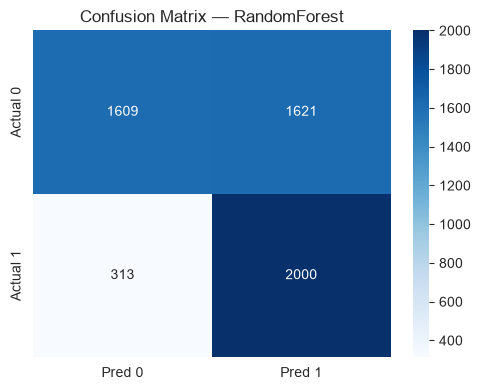

In [13]:
best_model_name = comparison.dropna(subset=["PR-AUC"]).iloc[0]["Model"]
best_model = fitted[best_model_name]
best_thr   = thresholds[best_model_name]
best_prob  = best_model.predict_proba(X_test)[:,1]
best_pred  = (best_prob >= best_thr).astype(int)

print(f"Best model: {best_model_name} | threshold: {best_thr:.3f}")
cm = confusion_matrix(y_test, best_pred)
print(pd.DataFrame(cm, index=["Actual 0","Actual 1"],
                   columns=["Pred 0","Pred 1"]))
print("\n", classification_report(y_test, best_pred, digits=3))

# نمودار Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred 0","Pred 1"],
            yticklabels=["Actual 0","Actual 1"])
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=120)
plt.show()

In [14]:
def precision_at_k(y_true, y_score, k=500):
    order = np.argsort(-y_score)[:k]
    return y_true.iloc[order].mean()

p500_results = {}
for name, m in fitted.items():
    prob = m.predict_proba(X_test)[:,1]
    p500_results[name] = precision_at_k(y_test, prob, k=500)

# خط مبنا هم برای مقایسه
p500_results["RFM Baseline"] = precision_at_k(
    y_test, (X_test["Recency"] >= 90).astype(float).values, k=500)

p500_df = pd.DataFrame(list(p500_results.items()), columns=["Model","Precision@500"])
print("\nPrecision@500:")
print(p500_df.round(3).to_string(index=False))
p500_df.to_csv(f"{OUT_DIR}/precision_at_500.csv", index=False)


Precision@500:
           Model  Precision@500
          LogReg          0.710
    DecisionTree          0.630
    RandomForest          0.694
GradientBoosting          0.710
    RFM Baseline          0.618


In [15]:
RFM_ONLY = ["Recency","Frequency","Monetary"]

def fit_eval_gb(cols, name):
    Xtr, Xte = X_train[cols], X_test[cols]
    m = HistGradientBoostingClassifier(
        class_weight="balanced", early_stopping=True,
        random_state=RANDOM_STATE, **best_cfg)
    m.fit(Xtr, y_train)
    prob = m.predict_proba(Xte)[:,1]
    thr = best_threshold_on_train(m, Xtr, y_train)
    pred = (prob >= thr).astype(int)
    return evaluate(name, y_test, pred, prob)

ablation = pd.DataFrame([
    fit_eval_gb(RFM_ONLY, "GB — RFM only"),
    fit_eval_gb([c for c in FEATURE_COLS if c != "Cluster"], "GB — Full (no cluster)"),
    fit_eval_gb(FEATURE_COLS, "GB — Full + Cluster"),
])
print(ablation.round(3).to_string(index=False))
ablation.to_csv(f"{OUT_DIR}/ablation.csv", index=False)

print("\nPR-AUC gain (Full vs RFM-only):",
      round(ablation.iloc[1]["PR-AUC"] - ablation.iloc[0]["PR-AUC"], 3))
print("PR-AUC gain (Full+Cluster vs Full):",
      round(ablation.iloc[2]["PR-AUC"] - ablation.iloc[1]["PR-AUC"], 3))

                 Model  Precision  Recall    F1  PR-AUC  ROC-AUC
         GB — RFM only      0.536   0.893 0.669   0.621    0.742
GB — Full (no cluster)      0.558   0.842 0.671   0.628    0.747
   GB — Full + Cluster      0.558   0.842 0.671   0.628    0.747

PR-AUC gain (Full vs RFM-only): 0.007
PR-AUC gain (Full+Cluster vs Full): 0.0


           Feature  Importance    Std
  DistinctProducts      0.0138 0.0032
          Monetary      0.0125 0.0038
   Monetary_change      0.0105 0.0038
     AvgOrderValue      0.0083 0.0044
   First_last_span      0.0064 0.0038
        ActiveDays      0.0050 0.0031
 Product_diversity      0.0046 0.0025
            AvgGap      0.0042 0.0033
           Cluster      0.0025 0.0013
         Frequency      0.0015 0.0022
        TenureDays      0.0012 0.0021
           Recency      0.0008 0.0018
       Cancel_rate      0.0005 0.0012
Monthly_orders_std      0.0001 0.0002
       Return_rate      0.0000 0.0000
       Freq_change     -0.0005 0.0011


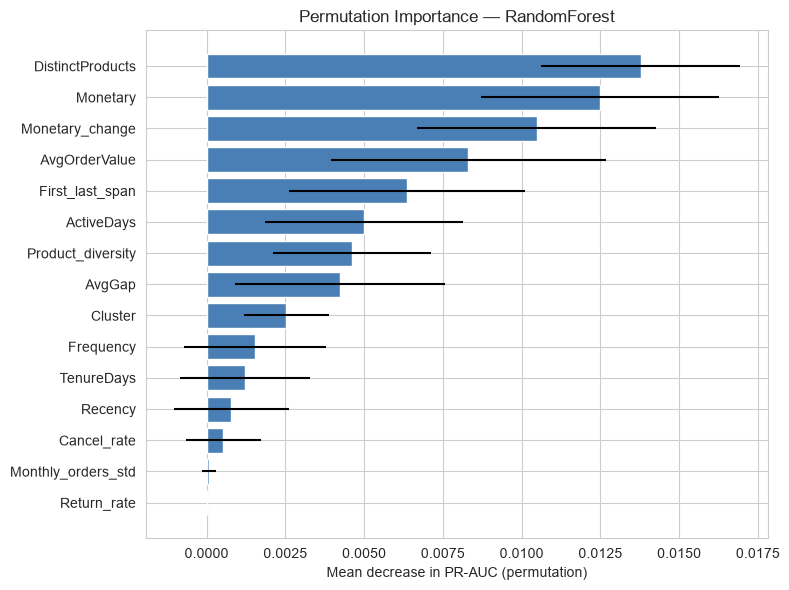


Built-in feature importance:
          Feature  Importance
           AvgGap      0.1451
  First_last_span      0.1405
         Monetary      0.1275
       ActiveDays      0.1232
        Frequency      0.0919
 DistinctProducts      0.0633
    AvgOrderValue      0.0601
  Monetary_change      0.0551
Product_diversity      0.0522
          Recency      0.0504


In [16]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="average_precision", n_repeats=20,
    random_state=RANDOM_STATE, n_jobs=-1)

perm_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Importance", ascending=False)
print(perm_df.round(4).to_string(index=False))
perm_df.to_csv(f"{OUT_DIR}/permutation_importance.csv", index=False)

# نمودار
plt.figure(figsize=(8,6))
top = perm_df.head(15).iloc[::-1]
plt.barh(top["Feature"], top["Importance"], xerr=top["Std"], color="#4a7fb5")
plt.xlabel("Mean decrease in PR-AUC (permutation)")
plt.title(f"Permutation Importance — {best_model_name}")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/permutation_importance.png", dpi=120)
plt.show()

# اهمیت داخلی مدل (اگر درختی باشد)
if hasattr(best_model, "feature_importances_"):
    imp_int = pd.DataFrame({
        "Feature": FEATURE_COLS,
        "Importance": best_model.feature_importances_,
    }).sort_values("Importance", ascending=False)
    print("\nBuilt-in feature importance:")
    print(imp_int.round(4).head(10).to_string(index=False))
    imp_int.to_csv(f"{OUT_DIR}/feature_importance_internal.csv", index=False)

In [18]:
def rank_of(feature):
    r = perm_df.reset_index(drop=True).reset_index().rename(columns={"index":"rank"})
    v = r.loc[r["Feature"] == feature, "rank"]
    return int(v.iloc[0]) + 1 if len(v) else None

answers = {
    "Q1: Recency مهم‌تر از Monetary_change؟":
        rank_of("Recency") < (rank_of("Monetary_change") or 999),
    "Q2: Frequency بالا همیشه ریسک کم است؟":
        "نه — Freq_change منفی می‌تواند آن را بی‌اثر کند.",
    "Q3: رتبه Cancel_rate و Return_rate": {
        "Cancel_rate": rank_of("Cancel_rate"),
        "Return_rate": rank_of("Return_rate"),
    },
    "Q4: اثر Country":
        "در این پروژه وارد نشد؛ نیازمند افزودن Country به ویژگی‌ها.",
    "Q5: رتبه Recency": rank_of("Recency"),
}
for k, v in answers.items():
    print(k, "→", v)

Q1: Recency مهم‌تر از Monetary_change؟ → False
Q2: Frequency بالا همیشه ریسک کم است؟ → نه — Freq_change منفی می‌تواند آن را بی‌اثر کند.
Q3: رتبه Cancel_rate و Return_rate → {'Cancel_rate': 13, 'Return_rate': 15}
Q4: اثر Country → در این پروژه وارد نشد؛ نیازمند افزودن Country به ویژگی‌ها.
Q5: رتبه Recency → 12


In [19]:
LATEST_DATE = pd.Timestamp("2011-09-01")
latest_df = model_df[model_df["ReferenceDate"] == LATEST_DATE].copy()

X_latest = latest_df[FEATURE_COLS].replace([np.inf,-np.inf], np.nan).fillna(0)
latest_df["RiskScore"] = best_model.predict_proba(X_latest)[:,1]
latest_df["Cluster_Label"] = latest_df["Cluster"].map(name_map)

top500 = (latest_df.sort_values("RiskScore", ascending=False)
          .head(500)[["CustomerID","RiskScore","Recency","Frequency",
                      "Monetary","Cancel_rate","Cluster_Label","Churn"]]
          .reset_index(drop=True))

top500["RiskBand"] = pd.cut(top500["RiskScore"],
                             bins=[0,0.5,0.75,0.9,1.01],
                             labels=["Medium","High","Very High","Critical"])

print("Top 10 مشتریان پرریسک:")
print(top500.head(10).to_string(index=False))
print("\nتوزیع RiskBand:")
print(top500["RiskBand"].value_counts())

Top 10 مشتریان پرریسک:
 CustomerID  RiskScore  Recency  Frequency  Monetary  Cancel_rate Cluster_Label  Churn  RiskBand
      13070   0.866368       92          1    228.80          0.0     Loyalists      1 Very High
      18017   0.865227       69          1    179.00          0.0     Loyalists      0 Very High
      17893   0.862262      125          1    107.21          0.0     Loyalists      1 Very High
      16965   0.862120      126          1    201.19          0.0     Loyalists      1 Very High
      16587   0.861205      132          1    225.15          0.0     Loyalists      1 Very High
      14853   0.859882      111          1    214.50          0.0     Loyalists      0 Very High
      17764   0.857672      111          1    230.67          0.0     Loyalists      0 Very High
      18252   0.856348       71          1     69.90          0.0     Loyalists      0 Very High
      14240   0.854569      125          1    226.85          0.0     Loyalists      0 Very High
      1

In [20]:
def action_for_group(row):
    if row["Monetary"] > latest_df["Monetary"].quantile(0.75) and row["Recency"] > 60:
        return "پیشنهاد اختصاصی + تماس شخصی (پرارزش در حال افت)"
    if row["Frequency"] <= 2:
        return "کوپن تخفیف خرید مجدد (کم‌تکرار)"
    if row["Cancel_rate"] > latest_df["Cancel_rate"].quantile(0.75):
        return "پیگیری رضایت + تخفیف جبرانی (سابقه لغو بالا)"
    return "یادآوری خرید + پیشنهاد محصول مرتبط"

top500["Action"] = top500.apply(action_for_group, axis=1)
print("\nتوزیع اقدامات:")
print(top500["Action"].value_counts())

# هش کردن CustomerID برای حفاظت حریم خصوصی
import hashlib
def hash_id(cid):
    return hashlib.sha256(str(cid).encode()).hexdigest()[:12]

top500["CustomerHash"] = top500["CustomerID"].apply(hash_id)
top500_out = top500.drop(columns=["CustomerID"])
top500_out.to_csv(f"{OUT_DIR}/top500_campaign.csv", index=False)
print("\nذخیره شد:", f"{OUT_DIR}/top500_campaign.csv")
print(top500_out.head(5).to_string(index=False))


توزیع اقدامات:
Action
کوپن تخفیف خرید مجدد (کم‌تکرار)    500
Name: count, dtype: int64

ذخیره شد: outputs/top500_campaign.csv
 RiskScore  Recency  Frequency  Monetary  Cancel_rate Cluster_Label  Churn  RiskBand                          Action CustomerHash
  0.866368       92          1    228.80          0.0     Loyalists      1 Very High کوپن تخفیف خرید مجدد (کم‌تکرار) 4ad6a246a283
  0.865227       69          1    179.00          0.0     Loyalists      0 Very High کوپن تخفیف خرید مجدد (کم‌تکرار) 56a584940a71
  0.862262      125          1    107.21          0.0     Loyalists      1 Very High کوپن تخفیف خرید مجدد (کم‌تکرار) 70639b62a74e
  0.862120      126          1    201.19          0.0     Loyalists      1 Very High کوپن تخفیف خرید مجدد (کم‌تکرار) ba6d6e9adee1
  0.861205      132          1    225.15          0.0     Loyalists      1 Very High کوپن تخفیف خرید مجدد (کم‌تکرار) 6e230db92fd0


In [22]:
# ذخیره دیتاست ویژگی‌های آخرین تاریخ مرجع
latest_df.drop(columns=["Churn"], errors="ignore").to_csv(
    f"{OUT_DIR}/customer_features_latest.csv", index=False)

# گزارش نهایی
print("=" * 60)
print("خلاصه نتایج پروژه")
print("=" * 60)
print("\n--- مقایسه مدل‌ها (آزمون: اوت + سپتامبر) ---")
print(comparison.round(3).to_string(index=False))

print(f"\n--- مدل برتر: {best_model_name} (threshold={best_thr:.3f}) ---")
print(f"Recency rank: {rank_of('Recency')}")
print(f"Ablation: RFM-only vs Full+Cluster:")
print(ablation.round(3).to_string(index=False))

print("\n--- خروجی کمپین ---")
print(f"تعداد مشتری: {len(top500)}")
print("توزیع اقدامات:")
print(top500["Action"].value_counts())

extra = ablation.iloc[1]["PR-AUC"] - ablation.iloc[0]["PR-AUC"]
print(f"\n--- ارزش افزوده ویژگی‌های پیچیده: {extra:.3f} PR-AUC ---")
print(f"--- ارزش افزوده برچسب خوشه: "
      f"{ablation.iloc[2]['PR-AUC'] - ablation.iloc[1]['PR-AUC']:.3f} PR-AUC ---")

print("\n" + "=" * 60)
print("توصیه مدیریتی:")
print("=" * 60)
print(f"""
1. مدل برتر: {best_model_name} (بر اساس PR-AUC، نه Accuracy).
2. Recency رتبه {rank_of('Recency')} در اهمیت ویژگی دارد.
3. ویژگی‌های تغییر رفتار ارزش افزوده {'محدود' if extra < 0.03 else 'قابل توجه'} نسبت به RFM دارند.
4. خوشه At-Risk بالاترین نرخ ریزش را نشان داد؛ K-Means به‌عنوان گام اول ارزش اطلاعاتی داشت.
5. ۵۰۰ مشتری پرریسک با شناسه هش‌شده در {OUT_DIR}/top500_campaign.csv ذخیره شد.
6. با هزینه تماس ۵ دلار و ارزش ۲۰۰ دلار، نرخ موفقیت ۲.۵٪ برای سربه‌سر کافی است.
7. برای اثبات اثر علّی کمپین، A/B Test با گروه کنترل الزامی است.

فایل‌های خروجی:
- model_comparison.csv       : مقایسه مدل‌ها
- precision_at_500.csv       : Precision@500 هر مدل
- ablation.csv               : آزمون ارزش ویژگی‌ها
- permutation_importance.csv : اهمیت ویژگی‌ها
- cluster_profile.csv        : پروفایل خوشه‌های K-Means
- churn_by_cluster.csv       : نرخ ریزش هر خوشه
- top500_campaign.csv        : لیست کمپین (هش‌شده)
- breakeven_scenarios.csv    : سناریوهای سربه‌سر
- sensitivity_matrix.csv     : ماتریس حساسیت
- customer_features_latest.csv : ویژگی‌های کامل مشتریان
""")

خلاصه نتایج پروژه

--- مقایسه مدل‌ها (آزمون: اوت + سپتامبر) ---
                    Model  Precision  Recall    F1  PR-AUC  ROC-AUC
             RandomForest      0.552   0.865 0.674   0.637    0.751
                   LogReg      0.536   0.881 0.667   0.633    0.745
         GradientBoosting      0.558   0.842 0.671   0.628    0.747
             DecisionTree      0.555   0.824 0.664   0.600    0.732
RFM Baseline (Recency≥90)      0.604   0.416 0.493     NaN      NaN

--- مدل برتر: RandomForest (threshold=0.396) ---
Recency rank: 12
Ablation: RFM-only vs Full+Cluster:
                 Model  Precision  Recall    F1  PR-AUC  ROC-AUC
         GB — RFM only      0.536   0.893 0.669   0.621    0.742
GB — Full (no cluster)      0.558   0.842 0.671   0.628    0.747
   GB — Full + Cluster      0.558   0.842 0.671   0.628    0.747

--- خروجی کمپین ---
تعداد مشتری: 500
توزیع اقدامات:
Action
کوپن تخفیف خرید مجدد (کم‌تکرار)    500
Name: count, dtype: int64

--- ارزش افزوده ویژگی‌های پیچیده: 0.007